# N4 — Colour- and position-controlled occlusion

Confirms the two findings from N3b's generalisation test under proper severity control.

### Why this is not simply "run black_center at higher levels"

The centre occluder's nominal level maps to a completely different severity than the edge one:

| nominal level | edge cells | centre cells |
|---|---|---|
| 0.10 | 0.0 | 12.8 |
| 0.20 | 1.7 | 22.9 |
| 0.30 | 5.7 | 29.6 |
| 0.50 | 18.0 | 36.0 (all) |

The reversal you want to confirm — published decoder 60.35% vs arm B 41.81% on black centre —
occurred at 12.8 occluded cells. Running centre at 0.20-0.50 gives 22.9 cells and up, where every
arm is already near zero and nothing is distinguishable. At 0.50 the marker is entirely hidden,
so 0% is correct behaviour rather than a failure.

**This notebook sweeps target occluded-cell counts** and solves for whichever nominal level
achieves each count, per position. Severity is then matched by construction.

### Two controlled contrasts

**Colour** (perfect control): identical position, identical geometry, identical occluded cells —
only appearance differs. N3b showed up to 47.5 pp from colour alone.

**Position** (matched severity): grey edge vs grey centre at equal cell counts. N3b's raw table
overstated this because of the severity confound; at ~12 cells the gap was 93.6% vs 64.7%.

Uses the N3b checkpoints. **Nothing is retrained.** `video_6` is untouched.

## 1. Setup

In [1]:
!pip -q install opencv-contrib-python==4.10.0.84 h5py 2>&1 | tail -1
print(">>> If OpenCV was just installed, RESTART THE RUNTIME, then continue.")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 68.7/68.7 MB 9.1 MB/s eta 0:00:00
>>> If OpenCV was just installed, RESTART THE RUNTIME, then continue.


### 1b. Port module

In [1]:
%%writefile /content/deeparuco_port.py
"""
Port the pretrained DeepArUco++ decoder from Keras .h5 to PyTorch, without TensorFlow.

The published decoder (models/dec_new.h5 in AVAuco/deeparuco) is a Keras 2.11 model:

    Input(32, 32, 1)
    Conv2D(8, 5x5, valid) -> PReLU -> MaxPool2D(2)
    Conv2D(4, 3x3, valid) -> PReLU -> MaxPool2D(2)
    Conv2D(1, 1x1, valid, sigmoid)   ->  (6, 6, 1)

Only h5py is needed to read the weights, so the repo's Python 3.9 + TensorFlow
environment is never required for baseline inference.

IMPORTANT PORTING DETAIL
    Keras PReLU defaults to shared_axes=None, so alpha is PER-ELEMENT, not per-channel:
    the stored alphas have shape (28, 28, 8) and (12, 12, 4). torch.nn.PReLU only
    supports per-channel alpha, so using it here silently produces a different model.
    SpatialPReLU below keeps the full alpha tensor.

Layout conversions:
    Keras conv kernel (kh, kw, in, out) -> torch (out, in, kh, kw)
    Keras PReLU alpha (h, w, c)         -> torch (c, h, w)
    Keras 'valid' padding               -> torch padding=0

Usage:
    from deeparuco_port import load_weights, NumpyDecoder, TorchDecoder, verify_port
    verify_port('models/dec_new.h5')          # run this first, once
    dec = TorchDecoder.from_h5('models/dec_new.h5')
    probs = dec(x)                            # x: (N, 1, 32, 32) float in [0, 1]

Upstream code is AGPL-3.0. This module reads a weights file; it does not copy source.
Cite Berral-Soler et al., Image and Vision Computing 152 (2024) 105313.
"""

import numpy as np

DEFAULT_H5 = "models/dec_new.h5"


# --------------------------------------------------------------------------- weights

def load_weights(h5_path=DEFAULT_H5):
    """Read decoder weights from the Keras .h5. Returns a dict of numpy arrays."""
    import h5py

    store = {}
    with h5py.File(h5_path, "r") as f:
        def visit(name, obj):
            if isinstance(obj, h5py.Dataset) and name.startswith("model_weights/"):
                store[name] = np.array(obj)
        f.visititems(visit)

    def pick(layer, suffix):
        hits = [k for k in store if f"/{layer}/" in k and k.endswith(suffix)]
        if len(hits) != 1:
            raise KeyError(f"expected one match for {layer}:{suffix}, got {hits}")
        return store[hits[0]]

    w = {
        "c1_w": pick("conv2d", "kernel:0"),   "c1_b": pick("conv2d", "bias:0"),
        "p1_a": pick("p_re_lu", "alpha:0"),
        "c2_w": pick("conv2d_1", "kernel:0"), "c2_b": pick("conv2d_1", "bias:0"),
        "p2_a": pick("p_re_lu_1", "alpha:0"),
        "c3_w": pick("conv2d_2", "kernel:0"), "c3_b": pick("conv2d_2", "bias:0"),
    }
    expect = {"c1_w": (5,5,1,8), "c1_b": (8,), "p1_a": (28,28,8),
              "c2_w": (3,3,8,4), "c2_b": (4,), "p2_a": (12,12,4),
              "c3_w": (1,1,4,1), "c3_b": (1,)}
    for k, shape in expect.items():
        assert w[k].shape == shape, f"{k}: got {w[k].shape}, expected {shape}"
    return w


# ------------------------------------------------------------------- numpy reference

class NumpyDecoder:
    """Reference implementation. Verified against synthetic markers: 4/5 exact."""

    def __init__(self, weights):
        self.w = weights

    @classmethod
    def from_h5(cls, path=DEFAULT_H5):
        return cls(load_weights(path))

    @staticmethod
    def _conv(x, w, b):
        kh, kw, _, co = w.shape
        H, W, _ = x.shape
        out = np.zeros((H - kh + 1, W - kw + 1, co), np.float32)
        for i in range(out.shape[0]):
            for j in range(out.shape[1]):
                out[i, j] = np.tensordot(
                    x[i:i+kh, j:j+kw, :], w, axes=([0, 1, 2], [0, 1, 2])) + b
        return out

    @staticmethod
    def _pool(x):
        h, w, c = x.shape
        return x.reshape(h // 2, 2, w // 2, 2, c).max(axis=(1, 3))

    def __call__(self, marker32):
        """marker32: (32, 32) float in [0, 1]. Returns (6, 6) bit probabilities."""
        w = self.w
        x = np.asarray(marker32, np.float32)[..., None]
        x = self._conv(x, w["c1_w"], w["c1_b"])
        x = np.where(x > 0, x, w["p1_a"] * x)
        x = self._pool(x)
        x = self._conv(x, w["c2_w"], w["c2_b"])
        x = np.where(x > 0, x, w["p2_a"] * x)
        x = self._pool(x)
        x = self._conv(x, w["c3_w"], w["c3_b"])
        return (1.0 / (1.0 + np.exp(-np.clip(x[..., 0], -60, 60)))).astype(np.float32)


# -------------------------------------------------------------------------- pytorch

def _torch():
    import torch
    import torch.nn as nn
    return torch, nn


class SpatialPReLU:
    """Created via _build so torch is imported lazily. See module docstring."""


def TorchDecoder_factory():
    torch, nn = _torch()

    class _SpatialPReLU(nn.Module):
        """Per-element PReLU, matching Keras PReLU(shared_axes=None)."""
        def __init__(self, alpha_chw):
            super().__init__()
            self.alpha = nn.Parameter(torch.tensor(alpha_chw, dtype=torch.float32))

        def forward(self, x):
            return torch.where(x > 0, x, self.alpha.unsqueeze(0) * x)

    class _TorchDecoder(nn.Module):
        def __init__(self, weights=None):
            super().__init__()
            self.c1 = nn.Conv2d(1, 8, 5)
            self.c2 = nn.Conv2d(8, 4, 3)
            self.c3 = nn.Conv2d(4, 1, 1)
            self.pool = nn.MaxPool2d(2)
            a1 = np.zeros((8, 28, 28), np.float32) if weights is None \
                 else np.transpose(weights["p1_a"], (2, 0, 1))
            a2 = np.zeros((4, 12, 12), np.float32) if weights is None \
                 else np.transpose(weights["p2_a"], (2, 0, 1))
            self.p1, self.p2 = _SpatialPReLU(a1), _SpatialPReLU(a2)
            if weights is not None:
                self.load_keras(weights)

        def load_keras(self, w):
            with torch.no_grad():
                for conv, kw, kb in ((self.c1, "c1_w", "c1_b"),
                                     (self.c2, "c2_w", "c2_b"),
                                     (self.c3, "c3_w", "c3_b")):
                    conv.weight.copy_(torch.tensor(np.transpose(w[kw], (3, 2, 0, 1))))
                    conv.bias.copy_(torch.tensor(w[kb]))

        @classmethod
        def from_h5(cls, path=DEFAULT_H5):
            return cls(load_weights(path))

        def forward(self, x):
            """x: (N, 1, 32, 32) in [0, 1]. Returns (N, 6, 6) bit probabilities."""
            x = self.pool(self.p1(self.c1(x)))
            x = self.pool(self.p2(self.c2(x)))
            return torch.sigmoid(self.c3(x)).squeeze(1)

    return _TorchDecoder


def __getattr__(name):
    if name == "TorchDecoder":
        return TorchDecoder_factory()
    raise AttributeError(name)


# --------------------------------------------------------------------------- verify

def verify_port(h5_path=DEFAULT_H5, n=16, tol=1e-4, verbose=True):
    """Assert the PyTorch port matches the numpy reference. Run once before use.

    The numpy path is validated; the torch path is validated against it here rather
    than assumed. Do not skip this.
    """
    torch, _ = _torch()
    w = load_weights(h5_path)
    ref = NumpyDecoder(w)
    net = TorchDecoder_factory()(w).eval()

    rng = np.random.default_rng(0)
    x = rng.random((n, 32, 32)).astype(np.float32)
    with torch.no_grad():
        got = net(torch.tensor(x).unsqueeze(1)).numpy()
    want = np.stack([ref(xi) for xi in x])

    err = float(np.abs(got - want).max())
    if verbose:
        print(f"port check: {n} random inputs, max abs difference {err:.2e} (tol {tol:g})")
    assert err < tol, f"PyTorch port disagrees with numpy reference (max diff {err:.2e})"
    if verbose:
        print("PyTorch port matches the numpy reference.")
    return err


def decode_ids(probs, id_to_bits, n_markers=250):
    """Hard-decision decode: nearest codeword by Hamming distance over 4 rotations.

    probs: (6, 6) bit probabilities. Returns (marker_id, rotation, hamming).
    Replace with soft log-likelihood decoding to use the confidences.
    """
    obs = (np.asarray(probs) > 0.5).astype(np.uint8)
    best = (None, None, 99)
    for mid in range(n_markers):
        ref = np.asarray(id_to_bits(mid), np.uint8).reshape(6, 6)
        for rot in range(4):
            h = int(np.sum(np.rot90(obs, rot) != ref))
            if h < best[2]:
                best = (mid, rot, h)
    return best


if __name__ == "__main__":
    import sys
    path = sys.argv[1] if len(sys.argv) > 1 else DEFAULT_H5
    w = load_weights(path)
    print("weights loaded:", {k: v.shape for k, v in w.items()})
    try:
        verify_port(path)
    except ImportError:
        print("torch not installed; numpy reference verified only")


Writing /content/deeparuco_port.py


In [2]:
import os, sys, json, glob, zlib, subprocess, time
import numpy as np, cv2, torch
import torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
from numpy.lib.stride_tricks import sliding_window_view
from google.colab import drive
drive.mount('/content/drive')

BASE  = '/content/drive/MyDrive/aruco_p2'
ART, WORK, CACHE = f'{BASE}/artifacts', '/content/work', f'{BASE}/archives'
CKPT  = f'{BASE}/ckpt_n3b'
os.makedirs(WORK, exist_ok=True); sys.path.insert(0, '/content')

REPO = f'{WORK}/deeparuco'
if not os.path.isdir(REPO):
    subprocess.run(['git','clone','--depth','1','https://github.com/AVAuco/deeparuco.git',REPO],check=True)
sys.path.insert(0, REPO)
from impl.aruco import id_to_bits
from deeparuco_port import load_weights, NumpyDecoder

DEV_ = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('torch', torch.__version__, '| device', DEV_)

splits = json.load(open(f'{ART}/splits.json'))
DEV, HELDOUT, STRIDE = splits['dev'], splits['heldout'][0], splits['benchmark_stride']
assert HELDOUT not in DEV
print('dev:', DEV, '| HELD OUT, not used here:', HELDOUT)

Wk  = load_weights(f'{REPO}/models/dec_new.h5')
CB  = np.stack([np.asarray(id_to_bits(i),np.uint8).reshape(6,6) for i in range(250)])
ROT = np.stack([np.rot90(CB,k,axes=(1,2)).reshape(250,36) for k in range(4)]).astype(np.float32)

SHADOW = f'{WORK}/shadow'; os.makedirs(SHADOW, exist_ok=True)
for i in range(1,7):
    if not os.path.isdir(f'{SHADOW}/video_{i}'):
        subprocess.run(['tar','-xzf',f'{CACHE}/video_{i}.tar.gz','-C',SHADOW], check=True)
print('data ready')

Mounted at /content/drive
torch 2.11.0+cpu | device cpu
dev: ['video_1', 'video_2', 'video_3', 'video_4', 'video_5'] | HELD OUT, not used here: video_6
data ready


## 2. Pipeline and models (loaded, not retrained)

In [3]:
r_int = lambda v: int(round(v))

def ordered_corners(xs, ys):
    cx, cy = np.mean(xs), np.mean(ys)
    idx = np.argsort(np.arctan2(xs-cx, ys-cy))
    return [v for i in idx for v in (xs[i], ys[i])]

def warp32(crop, c, t=32):
    dst = np.array([[0,0],[0,t-1],[t-1,t-1],[t-1,0]], np.float32)
    src = np.clip(np.array([[c[0]*63,c[1]*63],[c[2]*63,c[3]*63],
                            [c[4]*63,c[5]*63],[c[6]*63,c[7]*63]]),0,63).astype(np.float32)
    return cv2.warpPerspective(crop, cv2.getPerspectiveTransform(src,dst), (t,t))

def get_corners(m):
    c = m['corners']
    if isinstance(c[0], dict): return np.array([[p['x'],p['y']] for p in c], np.float32)
    return np.asarray(c, np.float32).reshape(4,2)

def cell_occlusion(m32):
    s = 32/8.0; out = np.zeros((6,6), bool)
    for r in range(6):
        for c in range(6):
            out[r,c] = m32[int((r+1)*s):int((r+2)*s), int((c+1)*s):int((c+2)*s)].mean() > 127.5
    return out

def prepare(img, mask, corners):
    x, y = corners[:,0], corners[:,1]
    mnx, mxx, mny, mxy = x.min(), x.max(), y.min(), y.max()
    ex, ey = 0.2*(mxx-mnx)+0.5, 0.2*(mxy-mny)+0.5
    mnx, mny = max(mnx-ex,0), max(mny-ey,0)
    mxx = min(mxx+ex, img.shape[1]-1); mxy = min(mxy+ey, img.shape[0]-1)
    if mxx-mnx < 8 or mxy-mny < 8: return None, None
    sl = (slice(r_int(mny), r_int(mxy)), slice(r_int(mnx), r_int(mxx)))
    crop = cv2.resize(img[sl], (64,64)).astype(np.float32)
    crop = (crop - crop.min())/(crop.max()-crop.min()+1e-9)
    nc = ordered_corners((x-mnx)/(mxx-mnx), (y-mny)/(mxy-mny))
    m32 = warp32(cv2.resize(mask[sl],(64,64)), nc) if mask.any() else np.zeros((32,32), np.uint8)
    return warp32(crop, nc), cell_occlusion(m32)

VALUES = {'grey': 127, 'black': 0, 'white': 255}

def occluder_box(img, corners, level, position, key, mid):
    """Geometry only — independent of colour, so colour is perfectly controlled."""
    if level <= 0: return None
    x, y = corners[:,0], corners[:,1]
    x0,x1,y0,y1 = x.min(),x.max(),y.min(),y.max(); w,h = x1-x0, y1-y0
    if position == 'edge':
        side = int(np.random.default_rng(zlib.crc32(f'occlusion|{level}|{key}|{mid}'.encode())).integers(0,4))
        box = [(x0,y0,x0+level*w,y1),(x1-level*w,y0,x1,y1),
               (x0,y0,x1,y0+level*h),(x0,y1-level*h,x1,y1)][side]
    else:                                   # centred box, side = level * extent
        cx, cy = (x0+x1)/2, (y0+y1)/2
        box = (cx-level*w/2, cy-level*h/2, cx+level*w/2, cy+level*h/2)
    a,b,c,d = [int(round(v)) for v in box]
    a,b = max(a,0),max(b,0); c,d = min(c,img.shape[1]),min(d,img.shape[0])
    return (a,b,c,d) if (c>a and d>b) else None

def apply_occluder(img, box, colour):
    if box is None: return img, np.zeros(img.shape[:2], np.uint8)
    a,b,c,d = box
    out = img.copy(); mk = np.zeros(img.shape[:2], np.uint8)
    out[b:d,a:c] = VALUES[colour]; mk[b:d,a:c] = 255
    return out, mk

def pairs_for(vid):
    out = []
    for f in sorted(glob.glob(f'{SHADOW}/{vid}/*.png')):
        j = f'{SHADOW}/{vid}/corrected_annotations/{os.path.splitext(os.path.basename(f))[0]}.json'
        if os.path.exists(j): out.append((f,j))
    return out

class SpatialPReLU(nn.Module):
    def __init__(s,c,h,w): super().__init__(); s.a = nn.Parameter(torch.zeros(c,h,w))
    def forward(s,x): return torch.where(x>0, x, s.a.unsqueeze(0)*x)

class Decoder(nn.Module):
    def __init__(s, out_ch=1):
        super().__init__()
        s.c1=nn.Conv2d(1,8,5); s.p1=SpatialPReLU(8,28,28)
        s.c2=nn.Conv2d(8,4,3); s.p2=SpatialPReLU(4,12,12)
        s.c3=nn.Conv2d(4,out_ch,1); s.out_ch=out_ch
    def forward(s,x):
        x=F.max_pool2d(s.p1(s.c1(x)),2); x=F.max_pool2d(s.p2(s.c2(x)),2); x=s.c3(x)
        return (x[:,0], x[:,1]) if s.out_ch==2 else (x[:,0], None)

models = {}
for arm, oc in [('B',1), ('D',2)]:
    p = f'{CKPT}/arm_{arm}.pt'
    assert os.path.exists(p), f'{p} missing — run N3b first'
    n = Decoder(oc).to(DEV_); n.load_state_dict(torch.load(p, map_location=DEV_)); n.eval()
    models[arm] = n
print('loaded arms B and D from N3b (no retraining)')

loaded arms B and D from N3b (no retraining)


## 3. Calibrate level -> occluded cells, per position

Solves for the nominal level that produces each target cell count. Geometry is independent of
colour, so one calibration per position serves all three colours and severity is matched exactly
across the colour contrast.

In [4]:
TARGETS = [3, 6, 9, 12, 15, 18]

cal_markers = []
for vid in DEV[:2]:
    for f, j in pairs_for(vid)[::STRIDE*8]:
        img = cv2.imread(f, cv2.IMREAD_GRAYSCALE)
        key = f'{vid}/{os.path.splitext(os.path.basename(f))[0]}'
        for m in json.load(open(j))['markers']:
            cal_markers.append((img, get_corners(m), key, int(m['id'])))
        if len(cal_markers) > 400: break
    if len(cal_markers) > 400: break
print(f'calibrating on {len(cal_markers)} markers\n')

def mean_cells(position, level):
    tot = n = 0
    for img, cn, key, mid in cal_markers:
        box = occluder_box(img, cn, level, position, key, mid)
        oi, om = apply_occluder(img, box, 'grey')
        _, occ = prepare(oi, om, cn)
        if occ is None: continue
        tot += occ.sum(); n += 1
    return tot/max(n,1)

LEVEL_FOR, ACHIEVED = {}, {}
for position in ('edge','center'):
    grid = np.arange(0.02, 0.70, 0.02)
    curve = [(float(L), mean_cells(position, float(L))) for L in grid]
    print(f'{position}: ' + ' '.join(f'{L:.2f}->{c:.1f}' for L,c in curve[::3]))
    for T in TARGETS:
        L, got = min(curve, key=lambda lc: abs(lc[1]-T))
        LEVEL_FOR[(position,T)] = L; ACHIEVED[(position,T)] = got
    print(f'  target -> level (achieved cells):')
    for T in TARGETS:
        got = ACHIEVED[(position,T)]
        flag = '   <-- POOR MATCH' if abs(got-T) > max(1.5, 0.25*T) else ''
        print(f'    {T:>3} cells -> L={LEVEL_FOR[(position,T)]:.2f}  (achieved {got:.1f}){flag}')
    dup = len(set(LEVEL_FOR[(position,T)] for T in TARGETS)) < len(TARGETS)
    if dup:
        print(f'  WARNING: {position} targets collapse onto duplicate levels — the occluder '
              f'cannot resolve these counts.\n  Rows sharing a level are the same experiment; '
              f'report achieved cells, not targets.')
    print()

print('Colour contrast is unaffected: geometry is identical across colours by construction.')
print('Position contrast is only valid where achieved cells are close between edge and centre —')
print('section 7 prints both, compare them before interpreting.')

calibrating on 405 markers

edge: 0.02->0.0 0.08->0.0 0.14->0.0 0.20->1.9 0.26->4.0 0.32->7.3 0.38->10.6 0.44->14.2 0.50->18.0 0.56->21.7 0.62->25.4 0.68->28.6
  target -> level (achieved cells):
      3 cells -> L=0.24  (achieved 3.3)
      6 cells -> L=0.30  (achieved 5.9)
      9 cells -> L=0.34  (achieved 8.5)
     12 cells -> L=0.40  (achieved 11.8)
     15 cells -> L=0.46  (achieved 15.7)
     18 cells -> L=0.50  (achieved 18.0)

center: 0.02->0.0 0.08->0.1 0.14->1.2 0.20->4.1 0.26->5.6 0.32->9.1 0.38->14.1 0.44->18.1 0.50->21.6 0.56->26.3 0.62->31.1 0.68->35.5
  target -> level (achieved cells):
      3 cells -> L=0.18  (achieved 3.4)
      6 cells -> L=0.28  (achieved 6.4)
      9 cells -> L=0.32  (achieved 9.1)
     12 cells -> L=0.36  (achieved 11.7)
     15 cells -> L=0.40  (achieved 15.4)
     18 cells -> L=0.44  (achieved 18.1)

Colour contrast is unaffected: geometry is identical across colours by construction.
Position contrast is only valid where achieved cells are clos

## 4. Build the evaluation set

One pass over the dev frames. For each marker and each (position, target) the occluder geometry
is computed once and the three colours are painted into the same region, so the colour contrast
holds cells occluded exactly constant.

Frame keys are stored so confidence intervals can be bootstrapped over frames — markers within a
frame are not independent, and a naive binomial interval would be too narrow.

In [5]:
CONFIGS = [(p, col, T) for p in ('edge','center') for col in ('grey','white','black') for T in TARGETS]
EVAL = {k: {'x':[], 'id':[], 'occ':[], 'frame':[]} for k in CONFIGS}
CLEAN = {'x':[], 'id':[], 'frame':[]}

t0 = time.time()
for vid in DEV:
    for f, j in pairs_for(vid)[::STRIDE]:
        img = cv2.imread(f, cv2.IMREAD_GRAYSCALE)
        key = f'{vid}/{os.path.splitext(os.path.basename(f))[0]}'
        for m in json.load(open(j))['markers']:
            cn, mid = get_corners(m), int(m['id'])
            x0, _ = prepare(img, np.zeros(img.shape[:2],np.uint8), cn)
            if x0 is None: continue
            CLEAN['x'].append((x0*255).astype(np.uint8)); CLEAN['id'].append(mid); CLEAN['frame'].append(key)
            for position in ('edge','center'):
                for T in TARGETS:
                    box = occluder_box(img, cn, LEVEL_FOR[(position,T)], position, key, mid)
                    for col in ('grey','white','black'):
                        oi, om = apply_occluder(img, box, col)
                        x32, occ = prepare(oi, om, cn)
                        if x32 is None: continue
                        k = (position, col, T)
                        EVAL[k]['x'].append((x32*255).astype(np.uint8))
                        EVAL[k]['id'].append(mid); EVAL[k]['occ'].append(occ.sum())
                        EVAL[k]['frame'].append(key)
    print(f'  {vid} ({time.time()-t0:.0f}s)')

for d in list(EVAL.values()) + [CLEAN]:
    for kk in d: d[kk] = np.array(d[kk])
print(f'\nclean: {len(CLEAN["id"])} markers | {len(CONFIGS)} configs')
print(f'memory ~{sum(v["x"].nbytes for v in EVAL.values())/1e6:.0f} MB')

  video_1 (92s)
  video_2 (160s)
  video_3 (244s)
  video_4 (328s)
  video_5 (397s)

clean: 12276 markers | 36 configs
memory ~453 MB


## 5. Decode and bootstrap

In [6]:
def _conv(x,w,b):
    kh,kw,_,_ = w.shape
    return np.einsum('nohckl,klci->nohi', sliding_window_view(x,(kh,kw),axis=(1,2)), w, optimize=True)+b
def _pool(x):
    N,H,Wd,Cc = x.shape; return x.reshape(N,H//2,2,Wd//2,2,Cc).max(axis=(2,4))
def decode_published(x8, chunk=4096):
    out=[]
    for s in range(0,len(x8),chunk):
        x = x8[s:s+chunk].astype(np.float32)[...,None]/255.0
        x = _pool(np.where((y:=_conv(x,Wk['c1_w'],Wk['c1_b']))>0,y,Wk['p1_a']*y))
        x = _pool(np.where((y:=_conv(x,Wk['c2_w'],Wk['c2_b']))>0,y,Wk['p2_a']*y))
        out.append(1/(1+np.exp(-np.clip(_conv(x,Wk['c3_w'],Wk['c3_b'])[...,0],-60,60))))
    return np.concatenate(out).astype(np.float32)

def decode_torch(net, x8, chunk=8192):
    ps, es = [], []
    with torch.no_grad():
        for s in range(0,len(x8),chunk):
            xb = torch.tensor(x8[s:s+chunk], dtype=torch.float32).unsqueeze(1).to(DEV_)/255.0
            lo, el = net(xb)
            ps.append(torch.sigmoid(lo).cpu().numpy())
            es.append(torch.sigmoid(el).cpu().numpy() if el is not None else np.zeros((len(lo),6,6),np.float32))
    return np.concatenate(ps), np.concatenate(es)

def dec_soft(P, Wt=None):
    LP = np.log(np.clip(P,1e-6,1)).reshape(len(P),36)
    LQ = np.log(np.clip(1-P,1e-6,1)).reshape(len(P),36)
    if Wt is not None:
        w = Wt.reshape(len(P),36); LP, LQ = LP*w, LQ*w
    return np.stack([LP@ROT[k].T + LQ@(1-ROT[k]).T for k in range(4)]).max(0).argmax(1)

def boot_ci(correct, frames, n=400, seed=0):
    """Cluster bootstrap over frames — markers within a frame are correlated."""
    rng = np.random.default_rng(seed)
    uf, inv = np.unique(frames, return_inverse=True)
    by = [np.where(inv==i)[0] for i in range(len(uf))]
    acc = []
    for _ in range(n):
        pick = rng.integers(0, len(by), len(by))
        idx = np.concatenate([by[p] for p in pick])
        acc.append(correct[idx].mean())
    return float(np.percentile(acc,2.5)), float(np.percentile(acc,97.5))

def evaluate(x8, ids, frames):
    Pa = decode_published(x8)
    Pb, _  = decode_torch(models['B'], x8)
    Pd, Ed = decode_torch(models['D'], x8)
    out = {}
    for name, pred in [('A', dec_soft(Pa)), ('B', dec_soft(Pb)),
                       ('D', dec_soft(Pd)), ('D_eras', dec_soft(Pd, 1-Ed))]:
        ok = (pred == ids)
        lo, hi = boot_ci(ok, frames)
        out[name] = (ok.mean(), lo, hi)
    return out

RES = {}
RES['clean'] = evaluate(CLEAN['x'], CLEAN['id'], CLEAN['frame'])
print('clean:', {k: f'{v[0]:.4f}' for k,v in RES['clean'].items()})
for i, k in enumerate(CONFIGS):
    d = EVAL[k]
    RES[k] = evaluate(d['x'], d['id'], d['frame'])
    RES[k]['cells'] = float(d['occ'].mean())
    if i % 6 == 0: print(f'  {i+1}/{len(CONFIGS)} done')
print('done')

clean: {'A': '0.9954', 'B': '0.9973', 'D': '0.9935', 'D_eras': '0.9935'}
  1/36 done
  7/36 done
  13/36 done
  19/36 done
  25/36 done
  31/36 done
done


## 6. Table 1 — colour contrast

Position, geometry and occluded cells identical within each row. **Only the occluder's colour
changes.** Grey is the training colour; white and black were never seen.

In [7]:
for position in ('edge','center'):
    print(f'\n{"="*96}\n{position.upper()} OCCLUDER — colour contrast at matched occluded cells\n{"="*96}')
    print(f"{'cells':>6} | {'grey (trained)':>26} | {'white':>26} | {'black':>26}")
    print(f"{'':>6} | {'A':>7}{'B':>9}{'D':>9} | {'A':>7}{'B':>9}{'D':>9} | {'A':>7}{'B':>9}{'D':>9}")
    print('-'*96)
    for T in TARGETS:
        cells = RES[(position,'grey',T)]['cells']
        line = f'{cells:>6.1f} |'
        for col in ('grey','white','black'):
            r = RES[(position,col,T)]
            line += f" {r['A'][0]:>6.1%}{r['B'][0]:>9.1%}{r['D_eras'][0]:>9.1%} |"
        print(line)

    print(f'\n  colour effect on arm B (grey -> white / black), same cells occluded:')
    for T in TARGETS:
        g, w, b = (RES[(position,c,T)]['B'] for c in ('grey','white','black'))
        cells = RES[(position,'grey',T)]['cells']
        print(f'   {cells:>5.1f} cells: grey {g[0]:>6.1%} [{g[1]:.1%},{g[2]:.1%}] | '
              f'white {(w[0]-g[0])*100:>+6.1f}pp | black {(b[0]-g[0])*100:>+6.1f}pp')


EDGE OCCLUDER — colour contrast at matched occluded cells
 cells |             grey (trained) |                      white |                      black
       |       A        B        D |       A        B        D |       A        B        D
------------------------------------------------------------------------------------------------
   3.2 |  85.7%    98.7%    93.5% |  76.7%    93.5%    82.8% |  96.4%    86.6%    88.0% |
   5.7 |  76.3%    96.4%    89.5% |  63.4%    88.1%    78.4% |  92.4%    79.6%    81.3% |
   8.5 |  65.4%    95.0%    88.0% |  51.1%    85.7%    76.8% |  84.4%    67.8%    70.9% |
  11.5 |  49.3%    93.0%    85.6% |  36.2%    82.8%    74.1% |  73.4%    58.7%    62.0% |
  15.6 |  32.4%    89.6%    81.9% |  21.5%    78.7%    70.2% |  55.3%    45.1%    48.5% |
  18.0 |  22.7%    83.2%    76.2% |  13.9%    72.5%    65.2% |  44.5%    38.2%    42.0% |

  colour effect on arm B (grey -> white / black), same cells occluded:
     3.2 cells: grey  98.7% [98.3%,98.9%] | whi

## 7. Table 2 — position contrast at matched severity

Grey occluder throughout; only edge vs centre differs, at equal occluded-cell counts. This is
the comparison N3b's raw table could not make.

In [8]:
print('POSITION CONTRAST — grey occluder, edge vs centre')
print(f"{'target':>7}{'edge c':>8}{'ctr c':>8}{'A edge':>9}{'A ctr':>9}{'B edge':>9}{'B ctr':>9}"
      f"{'D edge':>9}{'D ctr':>9}{'B gap':>9}{'matched':>9}")
print('-'*95)
for T in TARGETS:
    e, c = RES[('edge','grey',T)], RES[('center','grey',T)]
    ok = abs(e['cells']-c['cells']) <= max(1.5, 0.20*max(e['cells'],1))
    print(f"{T:>7}{e['cells']:>8.1f}{c['cells']:>8.1f}{e['A'][0]:>9.1%}{c['A'][0]:>9.1%}"
          f"{e['B'][0]:>9.1%}{c['B'][0]:>9.1%}{e['D_eras'][0]:>9.1%}{c['D_eras'][0]:>9.1%}"
          f"{(c['B'][0]-e['B'][0])*100:>8.1f}p{str(ok):>9}")
print('\nOnly rows with matched=True support a position claim. Where the achieved cell counts')
print('differ, the centre column is simply a more severe corruption and the gap is not a')
print('generalisation result — that was the confound in N3b.')

POSITION CONTRAST — grey occluder, edge vs centre
 target  edge c   ctr c   A edge    A ctr   B edge    B ctr   D edge    D ctr    B gap  matched
-----------------------------------------------------------------------------------------------
      3     3.2     3.4    85.7%    73.6%    98.7%    82.3%    93.5%    74.7%   -16.4p     True
      6     5.7     6.7    76.3%    52.9%    96.4%    75.3%    89.5%    74.1%   -21.1p     True
      9     8.5     9.2    65.4%    47.0%    95.0%    69.9%    88.0%    71.9%   -25.1p     True
     12    11.5    11.9    49.3%    39.9%    93.0%    66.6%    85.6%    68.9%   -26.4p     True
     15    15.6    15.8    32.4%    29.6%    89.6%    65.9%    81.9%    67.8%   -23.7p     True
     18    18.0    18.9    22.7%    21.0%    83.2%    58.3%    76.2%    61.7%   -24.8p     True

Only rows with matched=True support a position claim. Where the achieved cell counts
differ, the centre column is simply a more severe corruption and the gap is not a
generalisation

## 8. The reversal

N3b found the published decoder beating arm B on black centre occluders at ~12.8 cells
(60.35% vs 41.81%). Confirmed only if the confidence intervals separate at more than one
severity.

In [9]:
print('BLACK CENTRE — published (A) vs occlusion-augmented (B), 95% CI over frames')
print(f"{'cells':>6}{'A':>22}{'B':>22}{'A - B':>12}{'separated':>11}")
print('-'*73)
n_rev = 0
for T in TARGETS:
    r = RES[('center','black',T)]
    a, b = r['A'], r['B']
    sep = a[1] > b[2]                      # A's lower bound above B's upper bound
    n_rev += sep
    print(f"{r['cells']:>6.1f}{a[0]:>10.1%} [{a[1]:.1%},{a[2]:.1%}]{b[0]:>10.1%} [{b[1]:.1%},{b[2]:.1%}]"
          f"{(a[0]-b[0])*100:>11.1f}p{str(sep):>11}")

print(f'\nseverities with a significant reversal: {n_rev}/{len(TARGETS)}')
if n_rev >= 2:
    print('CONFIRMED — the published decoder beats the occlusion-augmented model on black')
    print('centre occluders. Occlusion augmentation can be actively harmful off-distribution.')
elif n_rev == 1:
    print('WEAK — a single severity. Report as suggestive, not established.')
else:
    print('NOT CONFIRMED — the N3b observation was a single-point artifact. Drop the claim.')

json.dump({'targets': TARGETS, 'levels': {f'{p}_{T}': LEVEL_FOR[(p,T)] for p in ('edge','center') for T in TARGETS},
           'results': {('clean' if k=='clean' else f'{k[0]}_{k[1]}_{k[2]}'):
                       {kk:(list(vv) if isinstance(vv,tuple) else vv) for kk,vv in v.items()}
                       for k,v in RES.items()},
           'n_reversals': int(n_rev), 'viewpoints': DEV, 'heldout_untouched': HELDOUT,
           'bootstrap': 'cluster over frames, 400 resamples'},
          open(f'{ART}/n4_controlled.json','w'), indent=1)
print(f'\nsaved -> {ART}/n4_controlled.json')

BLACK CENTRE — published (A) vs occlusion-augmented (B), 95% CI over frames
 cells                     A                     B       A - B  separated
-------------------------------------------------------------------------
   3.4     95.5% [95.0%,96.0%]     83.1% [81.8%,84.3%]       12.4p       True
   6.7     86.6% [85.3%,87.7%]     71.5% [70.0%,72.7%]       15.1p       True
   9.2     79.1% [77.6%,80.2%]     56.5% [54.9%,57.8%]       22.5p       True
  11.9     66.2% [64.7%,67.4%]     40.8% [39.3%,41.9%]       25.5p       True
  15.8     46.1% [44.7%,47.4%]     27.2% [25.9%,28.4%]       19.0p       True
  18.9     22.6% [21.7%,23.5%]     11.3% [10.6%,11.9%]       11.4p       True

severities with a significant reversal: 6/6
CONFIRMED — the published decoder beats the occlusion-augmented model on black
centre occluders. Occlusion augmentation can be actively harmful off-distribution.

saved -> /content/drive/MyDrive/aruco_p2/artifacts/n4_controlled.json


## 9. Figure

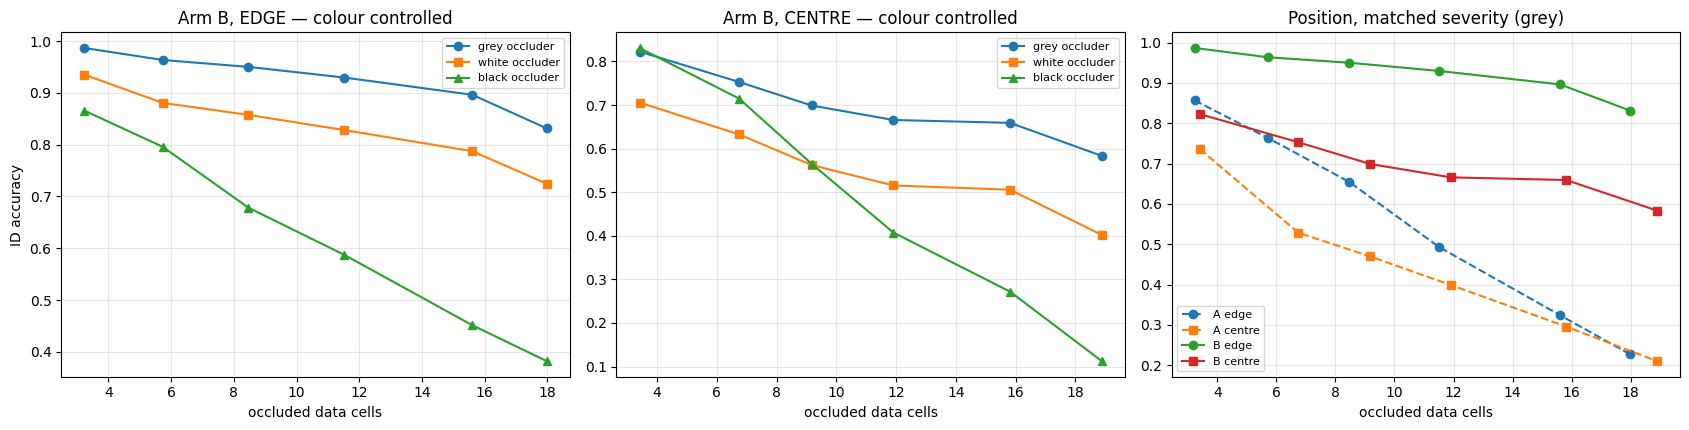

In [10]:
fig, ax = plt.subplots(1, 3, figsize=(17,4.4))
cells = [RES[('edge','grey',T)]['cells'] for T in TARGETS]
for col, style in [('grey','-o'), ('white','-s'), ('black','-^')]:
    ax[0].plot(cells, [RES[('edge',col,T)]['B'][0] for T in TARGETS], style, label=f'{col} occluder')
ax[0].set_xlabel('occluded data cells'); ax[0].set_ylabel('ID accuracy')
ax[0].set_title('Arm B, EDGE — colour controlled'); ax[0].legend(fontsize=8); ax[0].grid(alpha=.3)

cc = [RES[('center','grey',T)]['cells'] for T in TARGETS]
for col, style in [('grey','-o'), ('white','-s'), ('black','-^')]:
    ax[1].plot(cc, [RES[('center',col,T)]['B'][0] for T in TARGETS], style, label=f'{col} occluder')
ax[1].set_xlabel('occluded data cells'); ax[1].set_title('Arm B, CENTRE — colour controlled')
ax[1].legend(fontsize=8); ax[1].grid(alpha=.3)

for arm, style in [('A','--'), ('B','-')]:
    ax[2].plot(cells, [RES[('edge','grey',T)][arm][0] for T in TARGETS], style+'o', label=f'{arm} edge')
    ax[2].plot(cc, [RES[('center','grey',T)][arm][0] for T in TARGETS], style+'s', label=f'{arm} centre')
ax[2].set_xlabel('occluded data cells'); ax[2].set_title('Position, matched severity (grey)')
ax[2].legend(fontsize=8); ax[2].grid(alpha=.3)
plt.tight_layout(); plt.show()